# Trabajo Práctico: Predicción de precios de casas

**Aprendizaje Automático 1**, Tecnicatura en Inteligencia Artificial
Facultad de Ciencias Exactas, Ingeniería y Agrimensura (UNR). 2026, cuatrimestre 2

**Integrantes:** Sofia Grando, Amanda Tardugno, Lucas Díaz y Facundo Ferreira

El objetivo es predecir `MEDV`, el valor mediano de las viviendas ocupadas por sus
propietarios (en miles de dólares), a partir de 13 características de la vivienda y de
su entorno. Es un problema de **regresión**: la variable a predecir es numérica y
continua.

El trabajo sigue este orden: análisis descriptivo y preprocesamiento de los datos,
implementación de la regresión lineal múltiple por distintos métodos (mínimos cuadrados,
gradiente descendiente y regularización), optimización de hiperparámetros y comparación
final de los modelos.

## Configuración del entorno

In [1]:
# Bibliotecas de manipulación, visualización y modelado usadas en todo el trabajo
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Fijamos estilo y semilla para que las figuras y los resultados sean reproducibles
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
SEMILLA = 42
np.random.seed(SEMILLA)
pd.set_option("display.width", 200)

## Carga e inspección estructural

In [3]:
# Cargamos el dataset, que vive en la misma carpeta que este notebook
df = pd.read_csv("house-prices-tp.csv")
df.head()

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.07151,0.0,4.49,0.0,0.449,6.121,56.8,3.7476,3.0,247.0,18.5,395.15,8.44,22.2
1,0.08265,0.0,13.92,0.0,0.437,6.127,18.4,5.5027,4.0,289.0,16.0,396.90,8.58,23.9
2,0.12816,12.5,6.07,0.0,0.409,5.885,33.0,6.4980,4.0,345.0,18.9,396.90,8.79,20.9
3,0.08873,21.0,5.64,0.0,0.439,5.963,45.7,6.8147,4.0,243.0,16.8,395.56,13.45,19.7
4,0.11432,0.0,8.56,0.0,0.520,6.781,71.3,2.8561,5.0,384.0,20.9,395.58,7.67,26.5


In [4]:
# Dimensiones y tipo de dato de cada variable
print(f"Filas: {df.shape[0]}  |  Columnas: {df.shape[1]}")
df.dtypes.to_frame("tipo")

Filas: 556  |  Columnas: 14


,tipo
CRIM,float64
ZN,float64
INDUS,float64
CHAS,float64
NOX,float64
RM,float64
AGE,float64
DIS,float64
RAD,float64
TAX,float64


In [5]:
# Verificamos que no haya filas repetidas, que inflarían artificialmente el entrenamiento
print(f"Filas duplicadas exactas: {df.duplicated().sum()}")

Filas duplicadas exactas: 0


### Las variables

Según el enunciado, las 13 características de entrada y la variable a predecir son:

| Variable | Significado |
|---|---|
| `CRIM` | Tasa de criminalidad per cápita por ciudad |
| `ZN` | Proporción de terrenos residenciales zonificados para lotes de más de 25.000 pies² |
| `INDUS` | Proporción de acres de negocios no minoristas por ciudad |
| `CHAS` | Variable *dummy* del río Charles (1 si el tramo limita con el río, 0 si no) |
| `NOX` | Concentración de óxidos de nitrógeno (partes por 10 millones) |
| `RM` | Número promedio de habitaciones por vivienda |
| `AGE` | Proporción de unidades ocupadas por sus propietarios construidas antes de 1940 |
| `DIS` | Distancias ponderadas a cinco centros de empleo de Boston |
| `RAD` | Índice de accesibilidad a las autopistas radiales |
| `TAX` | Tasa de impuesto sobre la propiedad a valor completo por cada $10.000 |
| `PTRATIO` | Proporción alumno-maestro por ciudad |
| `B` | Resultado de la ecuación B = 1000(Bk − 0,63)², con Bk la proporción de negros por ciudad |
| `LSTAT` | Porcentaje de población de menor estatus socioeconómico |
| **`MEDV`** | **Valor mediano de las viviendas, en miles de dólares, variable a predecir** |

Todas quedaron como numéricas, y es lo correcto: no hay variables de texto ni categóricas
nominales que haya que codificar. Dos merecen una aclaración:

- **`CHAS`** es una *dummy* que ya viene codificada como 0/1, así que no requiere ningún
  tratamiento adicional.
- **`RAD`** es un índice entero de accesibilidad. Aunque toma pocos valores distintos, es
  ordinal (un índice más alto significa más accesibilidad), así que tratarla como numérica
  preserva ese orden. Codificarla como categórica lo perdería y agregaría columnas sin
  necesidad.

Sobre `B`: es una variable construida a partir de la composición racial de cada barrio y
es la más cuestionada de este dataset, tanto por lo que codifica como por la
transformación cuadrática que la vuelve difícil de interpretar. La conservamos porque el
enunciado la lista entre las características de entrada, pero vale tenerla presente al
leer los coeficientes del modelo.

## Análisis descriptivo

In [6]:
# Medidas de tendencia central y dispersión de todas las variables
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
CRIM,533.0,5.85,13.83,0.01,0.08,0.32,4.87,88.98
ZN,534.0,13.20,24.90,0.00,0.00,0.00,20.00,100.00
INDUS,541.0,11.22,6.94,0.46,5.13,9.69,18.10,27.74
CHAS,533.0,0.09,0.29,0.00,0.00,0.00,0.00,1.00
NOX,532.0,0.56,0.12,0.38,0.45,0.54,0.64,0.87
RM,535.0,6.29,0.78,3.56,5.88,6.21,6.64,8.78
AGE,532.0,67.63,28.46,2.90,42.28,76.50,93.82,100.00
DIS,541.0,3.94,2.26,1.13,2.11,3.34,5.40,12.13
RAD,528.0,9.70,8.68,1.00,4.00,5.00,23.63,24.00
TAX,538.0,409.58,167.69,187.00,279.00,335.00,666.00,711.00


In [7]:
# El sesgo mide la asimetría de cada distribución: lejos de 0 indica una cola larga
df.skew().sort_values(ascending=False).to_frame("sesgo").round(2)

,sesgo
CRIM,3.75
CHAS,2.87
ZN,1.96
DIS,1.08
MEDV,1.06
RAD,0.95
LSTAT,0.95
NOX,0.69
TAX,0.63
RM,0.37


### Lectura del descriptivo

Las escalas son muy distintas entre sí. `TAX` va de 187 a 711 y `B` llega a 396,9,
mientras que `NOX` se mueve entre 0,38 y 0,87 y `CHAS` es 0 o 1. Esa diferencia de
órdenes de magnitud no afecta a la regresión lineal por mínimos cuadrados, pero sí al
gradiente descendiente (que converge mal cuando las variables tienen escalas dispares) y
sobre todo a la regularización, donde la penalización mira el tamaño numérico del
coeficiente: sin escalar, castigaría más a las variables de valores chicos sólo por estar
medidas en otra unidad. Por eso vamos a escalar antes de esos modelos (ítem 4).

Varias distribuciones son fuertemente asimétricas. `CRIM` tiene mediana 0,32 pero
máximo 88,98: la mayoría de los barrios tiene criminalidad baja y unos pocos valores muy
altos estiran la cola. Algo parecido pasa con `ZN` (mediana 0) y `CHAS` (sólo ~9% de los
barrios linda con el río). Conviene tenerlo en cuenta al decidir el tratamiento de
outliers: en estas variables los valores extremos no son necesariamente errores de carga,
sino barrios que efectivamente son atípicos.

`MEDV` llega justo hasta 50. Con mediana 21,2, que el máximo sea un número tan redondo
llama la atención: si los valores altos se repartieran como en cualquier variable continua,
no habría motivo para que se detengan exactamente ahí.

In [8]:
# Contamos cuántas viviendas caen exactamente en el valor máximo de la escala
tope = (df["MEDV"] == 50).sum()
print(f"Viviendas con MEDV = 50: {tope} ({tope / df['MEDV'].notna().sum():.1%} de las observadas)")

Viviendas con MEDV = 50: 16 (3.0% de las observadas)


Son 16 viviendas, el 3% de las observadas, apiladas exactamente en 50 en lugar de
repartirse por encima. No es una casualidad de la muestra: es un tope impuesto al construir
el dataset, donde todo lo que valía más se registró como 50.

Para el modelo significa que en esa franja el valor real es desconocido, y que el error ahí
va a ser sistemático: ninguna recta puede acertarle a barrios cuyo precio verdadero está
oculto detrás de un tope. Lo tenemos en cuenta al leer las métricas del ítem 4.

## Análisis y decisión sobre datos faltantes

In [9]:
# Cantidad y porcentaje de valores faltantes en cada variable
faltantes = df.isna().sum()
pd.DataFrame({"faltantes": faltantes,
              "% del total": (faltantes / len(df) * 100).round(1)})

,faltantes,% del total
CRIM,23,4.1
ZN,22,4.0
INDUS,15,2.7
CHAS,23,4.1
NOX,24,4.3
RM,21,3.8
AGE,24,4.3
DIS,15,2.7
RAD,28,5.0
TAX,18,3.2


In [10]:
# Cuántos valores le faltan a cada fila: revela si los faltantes se concentran o se dispersan
por_fila = df.isna().sum(axis=1)
print(f"Celdas faltantes en total: {int(faltantes.sum())}")
print(f"Filas completas: {(por_fila == 0).sum()}  |  Filas con al menos un faltante: {(por_fila > 0).sum()}")
por_fila[por_fila > 0].value_counts().sort_index().to_frame("cantidad de filas").rename_axis("faltantes en la fila")

Celdas faltantes en total: 306
Filas completas: 506  |  Filas con al menos un faltante: 50


,cantidad de filas
faltantes en la fila,
1,5
2,3
3,11
4,3
5,3
6,2
7,5
8,4
9,4


### Diagnóstico

Los faltantes **no están repartidos al azar**:

- Las 306 celdas faltantes se concentran en **apenas 50 filas**. Las otras 506 están
  completas, sin un solo valor ausente.
- Esas 50 filas están muy deterioradas: en promedio les faltan 6 de sus 14 valores, y hay
  tres a las que le faltan 13 columnas y una a la que le faltan las 14.
- En 21 de ellas la que falta es `MEDV`, la variable que hay que predecir.

### Decisión

Eliminamos toda fila que tenga al menos un valor faltante. Quedan las 506 filas
completas, el 91% del conjunto original.

Imputar supone que la fila conserva información suficiente para estimar lo que falta, y no
es el caso: a estas filas les falta en promedio un valor de cada dos y a varias casi todo.
Lo que se imputara no describiría a ese barrio sino al método de imputación, y entrenar
sobre eso agrega ruido disfrazado de datos.

Las 21 filas sin `MEDV` se eliminan además por una razón más categórica, que vale aunque el
resto de la fila esté completo: `MEDV` es la variable que el modelo debe aprender a
predecir. Completarla con una estimación nuestra sería entrenar al modelo contra nuestra
propia invención en lugar de contra un dato real, y si alguna de esas filas cayera en el
conjunto de prueba, estaríamos midiendo el error contra un valor inventado.

El costo es perder 50 filas, un 9% del total. Es asumible: las 506 que quedan están
completas, así que a partir de acá no hay ningún valor ausente que arrastrar.

In [11]:
# Nos quedamos con las filas completas, que es el criterio de limpieza que adoptamos
df_limpio = df.dropna().reset_index(drop=True)
print(f"Filas antes: {len(df)}  |  Filas después: {len(df_limpio)}  |  Eliminadas: {len(df) - len(df_limpio)}")
print(f"Valores faltantes restantes: {int(df_limpio.isna().sum().sum())}")

Filas antes: 556  |  Filas después: 506  |  Eliminadas: 50
Valores faltantes restantes: 0


## División en entrenamiento y prueba

Dividimos **acá**, apenas eliminadas las filas incompletas y **antes** de escalar o mirar
correlaciones, para evitar *data leakage*. Escalar no es una operación neutra:
calcula parámetros a partir de los datos: la media y el desvío de cada variable. Si esos
parámetros se calculan sobre el conjunto completo, los datos de prueba participan del
preprocesamiento y dejan de ser datos nuevos para el modelo. El resultado es una métrica
de prueba optimista, que no anticipa cómo se va a comportar el modelo con datos que nunca
vio. Por eso todo lo que **aprende** algo de los datos se ajusta sobre entrenamiento y sólo
se **aplica** a prueba.

Eliminar filas, en cambio, sí podía hacerse antes: es un filtro por una condición fija que
no estima ningún parámetro, así que no transfiere información entre los conjuntos.

Usamos 80% para entrenamiento y 20% para prueba, dentro del rango habitual de 15–30%, y fijamos `random_state` para que la partición sea reproducible.

In [12]:
# Separamos las características de la variable a predecir
from sklearn.model_selection import train_test_split

X = df_limpio.drop(columns="MEDV")
y = df_limpio["MEDV"]

In [13]:
# Dividimos en entrenamiento y prueba antes de cualquier transformación que aprenda parámetros
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEMILLA
)
print(f"Entrenamiento: {X_train.shape[0]} filas  |  Prueba: {X_test.shape[0]} filas")

Entrenamiento: 404 filas  |  Prueba: 102 filas


## Visualización de los datos

Graficamos **sólo el conjunto de entrenamiento**: mirar el de prueba para tomar decisiones
de modelado es una forma sutil de filtración, porque esas decisiones terminan incorporando
información que se supone que no conocemos.

In [14]:
# Unimos features y target del entrenamiento para poder graficar las relaciones con MEDV
train = X_train.copy()
train["MEDV"] = y_train

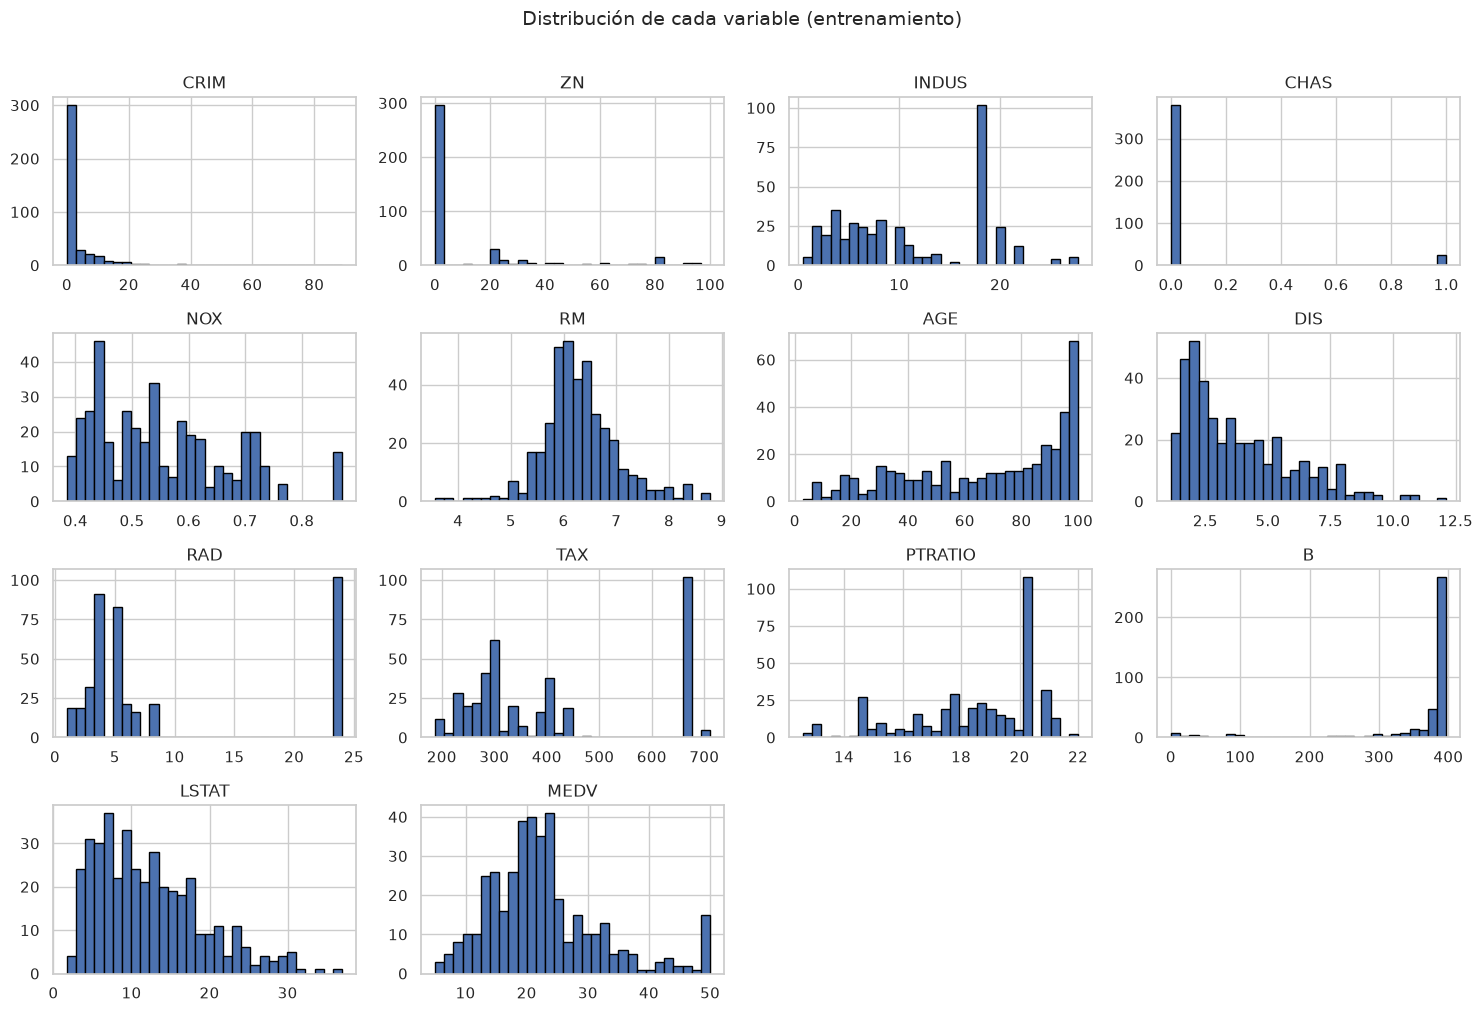

In [15]:
# Histogramas de todas las variables para ver la forma de cada distribución
train.hist(bins=30, figsize=(15, 10), edgecolor="black")
plt.suptitle("Distribución de cada variable (entrenamiento)", y=1.01, fontsize=14)
plt.tight_layout()
plt.show()

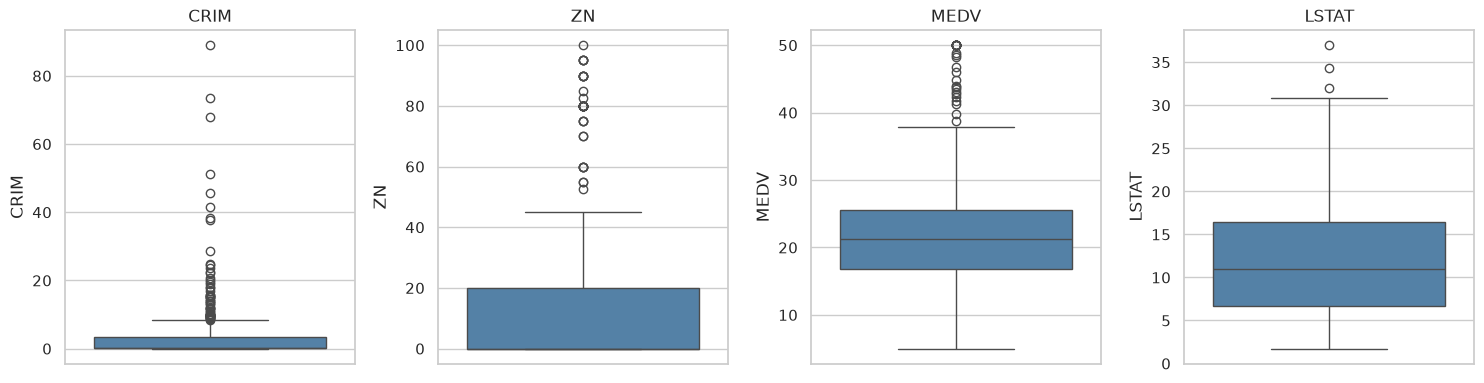

In [16]:
# Diagramas de caja de las variables más asimétricas, para dimensionar los valores atípicos
fig, axes = plt.subplots(1, 4, figsize=(15, 4))
for ax, col in zip(axes, ["CRIM", "ZN", "MEDV", "LSTAT"]):
    sns.boxplot(y=train[col], ax=ax, color="steelblue")
    ax.set_title(col)
plt.tight_layout()
plt.show()

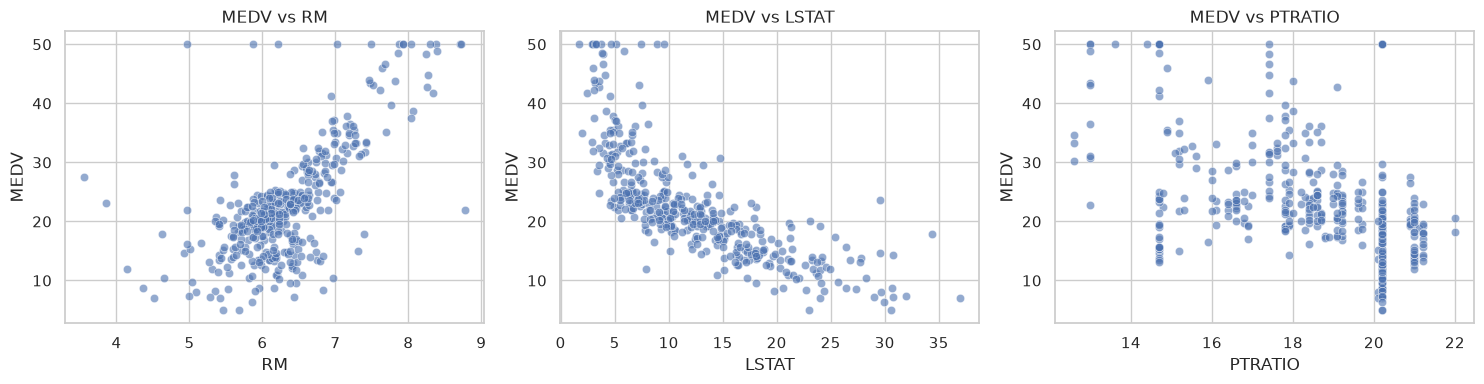

In [17]:
# Dispersión de MEDV contra las variables más correlacionadas, para ver si la relación es lineal
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["RM", "LSTAT", "PTRATIO"]):
    sns.scatterplot(data=train, x=col, y="MEDV", ax=ax, alpha=0.6)
    ax.set_title(f"MEDV vs {col}")
plt.tight_layout()
plt.show()

### Lectura de los gráficos

Los histogramas confirman lo que anticipaba el sesgo: `CRIM` y `ZN` se acumulan cerca de
cero con colas largas, y `CHAS` es casi toda ceros. En `MEDV` se ve con claridad la barra
del tope en 50, que no continúa una distribución decreciente sino que la interrumpe: es el
truncamiento, no un grupo natural de viviendas caras.

Los diagramas de caja marcan **muchos puntos fuera de los bigotes**, sobre todo en `CRIM`.
Decidimos **no eliminarlos**. En una variable como criminalidad per cápita, un valor alto
no es un error de carga sino un barrio que realmente tiene esa tasa, y son justamente los
barrios que el modelo necesita poder predecir. Recortarlos mejoraría las métricas
artificialmente, entrenando y evaluando sobre una versión del problema más fácil que la
real.

Los diagramas de dispersión muestran las dos relaciones más aprovechables para un modelo
lineal: `RM` sube con `MEDV` (más habitaciones, más valor) y `LSTAT` baja (más población
de menor estatus socioeconómico, menos valor). La relación de `LSTAT` se ve levemente
curva, lo cual anticipa que un modelo lineal va a tener algo de error sistemático en los
extremos. La franja horizontal de puntos en `MEDV` = 50 vuelve a aparecer en los tres
gráficos.

## Matriz de correlación

Miramos dos cosas: qué características se relacionan más con `MEDV`, y cuáles están muy
correlacionadas **entre sí**. Lo segundo importa porque cuando
dos variables son casi combinación lineal una de otra los coeficientes del modelo se
vuelven inestables: el ajuste puede repartir el peso entre ambas de infinitas maneras
equivalentes.

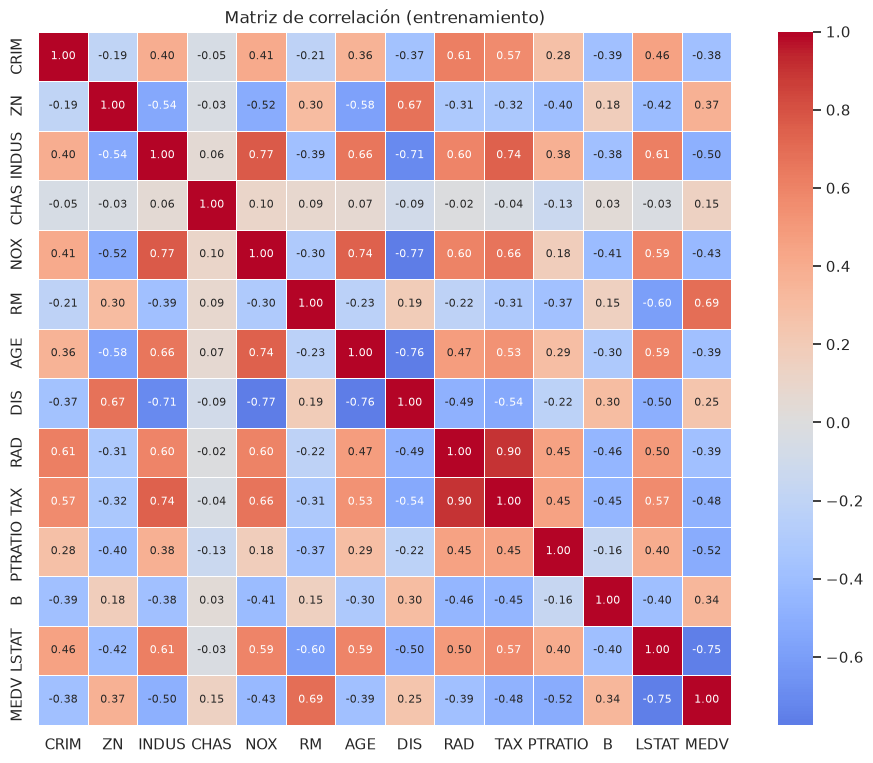

In [18]:
# Matriz de correlación de Pearson sobre el entrenamiento
correlacion = train.corr()
plt.figure(figsize=(12, 9))
sns.heatmap(correlacion, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            square=True, linewidths=0.5, annot_kws={"size": 8})
plt.title("Matriz de correlación (entrenamiento)")
plt.show()

In [19]:
# Ordenamos la correlación de cada característica con la variable a predecir
correlacion["MEDV"].drop("MEDV").sort_values(key=abs, ascending=False).to_frame("correlación con MEDV").round(3)

,correlación con MEDV
LSTAT,-0.753
RM,0.692
PTRATIO,-0.523
INDUS,-0.495
TAX,-0.481
NOX,-0.433
AGE,-0.386
RAD,-0.386
CRIM,-0.385
ZN,0.367


In [20]:
# Buscamos pares de características muy correlacionadas entre sí, que causan coeficientes inestables
import itertools

pares = [(a, b, correlacion.loc[a, b]) for a, b in itertools.combinations(X.columns, 2)
         if abs(correlacion.loc[a, b]) > 0.7]
pd.DataFrame(pares, columns=["variable A", "variable B", "correlación"]).round(3)

,variable A,variable B,correlación
0,INDUS,NOX,0.770
1,INDUS,DIS,-0.707
2,INDUS,TAX,0.741
3,NOX,AGE,0.741
4,NOX,DIS,-0.773
5,AGE,DIS,-0.764
6,RAD,TAX,0.900


### Lectura de la correlación

Las dos relaciones más fuertes con `MEDV` son `LSTAT` (−0,74) y `RM` (0,68), consistentes
con lo que mostraban los diagramas de dispersión. Les siguen `PTRATIO` (−0,51) y `TAX`
(−0,46). La más débil es `CHAS` (0,19): lindar con el río prácticamente no distingue el
valor de una vivienda. Ninguna característica tiene correlación nula con `MEDV`, así que no
hay ninguna que descartar por irrelevante.

Entre las características también aparece colinealidad apreciable, y el caso más marcado es
`RAD`–`TAX` (0,89): los barrios con más accesibilidad a autopistas son también los de mayor
carga impositiva. `INDUS` se relaciona fuerte con `NOX` (0,76) y `TAX` (0,75), lo que tiene
sentido: más actividad industrial va junto con más contaminación.

Conservamos las dos variables de cada par. La colinealidad no impide ajustar el modelo pero
vuelve inestables los coeficientes, porque el ajuste puede repartir el peso entre las
variables correlacionadas de muchas maneras casi equivalentes. Eliminar una a mano sería
una decisión arbitraria sobre cuál de las dos importa, y es exactamente el escenario en el
que la regularización rinde: Ridge funciona bien cuando los coeficientes tienen mucha
varianza, que es lo que produce la colinealidad. Queda como hipótesis a verificar en el
ítem 4, cuando comparemos Ridge contra la regresión sin regularizar.

## Codificación de variables categóricas

En este dataset **no hace falta ninguna codificación**:

- Las catorce columnas llegaron como numéricas y ese tipo es el correcto en todos los
  casos; no hay ninguna columna de texto ni ninguna categoría nominal.
- `CHAS` es la única variable categórica del conjunto, pero es binaria y **ya viene
  codificada** como 0/1, que es exactamente el resultado que produciría aplicarle
  codificación *dummy*.
- `RAD` toma pocos valores distintos, pero es un índice **ordinal**: un valor más alto
  significa mayor accesibilidad a las autopistas. Tratarla como numérica conserva ese
  orden, que es información útil para el modelo. Aplicarle *one-hot encoding* la
  convertiría en columnas sin relación entre sí, perdiendo el orden y sumando dimensiones
  sin ganar nada.

## Escalado de los datos

Estandarizamos restando la media y dividiendo por el desvío de cada variable, de modo que
todas queden en una escala comparable. Es indispensable para el gradiente descendiente (con
escalas dispares la convergencia se vuelve lenta e inestable) y para la regularización,
donde la penalización compara los coeficientes entre sí y sin escalar castigaría a unas
variables más que a otras sólo por la unidad en la que están medidas. También escalamos
`CHAS`: al ser binaria el cambio es cosmético, pero incluirla evita tener que tratar esa
columna por separado.

El escalador aprende dos parámetros de los datos, la media y el desvío de cada variable,
así que lo **ajustamos sólo sobre entrenamiento** y después lo aplicamos a prueba tal cual
quedó ajustado.

In [21]:
# Escalador que estandariza cada variable y devuelve el resultado como DataFrame
from sklearn.preprocessing import StandardScaler

escalador = StandardScaler().set_output(transform="pandas")

In [22]:
# Ajustamos sobre entrenamiento y sólo aplicamos sobre prueba, para no filtrar información
X_train_prep = escalador.fit_transform(X_train)
X_test_prep = escalador.transform(X_test)
print(f"Entrenamiento: {X_train_prep.shape[0]} filas  |  Prueba: {X_test_prep.shape[0]} filas")

Entrenamiento: 404 filas  |  Prueba: 102 filas


In [23]:
# Verificamos el escalado: entrenamiento queda centrado en 0 con desvío 1, prueba sólo aproximadamente
pd.DataFrame({"media train": X_train_prep.mean(), "desvío train": X_train_prep.std(),
              "media test": X_test_prep.mean(), "desvío test": X_test_prep.std()}).round(3)

,media train,desvío train,media test,desvío test
CRIM,-0.0,1.001,-0.057,0.588
ZN,0.0,1.001,-0.112,0.806
INDUS,-0.0,1.001,0.109,0.990
CHAS,-0.0,1.001,0.205,1.319
NOX,-0.0,1.001,0.085,0.932
RM,-0.0,1.001,-0.189,0.821
AGE,0.0,1.001,0.125,0.991
DIS,0.0,1.001,-0.088,0.926
RAD,-0.0,1.001,0.102,1.041
TAX,-0.0,1.001,0.053,1.031


La última tabla es la confirmación de que no hubo filtración. El conjunto de
entrenamiento queda con media exactamente 0 y desvío 1, porque es el que se usó para
calcular esos parámetros. (La tabla muestra 1,001 y no 1 por una diferencia de convención:
`StandardScaler` divide por el desvío poblacional y `pandas` informa el muestral.) El de prueba queda **cerca** de 0 y 1 pero no exacto, que es
justamente lo que se espera: sus valores fueron transformados con la media y el desvío del
entrenamiento, sin que sus propios datos participaran del cálculo. Si esta tabla diera 0 y
1 exactos en ambas columnas, sería señal de haber escalado todo junto y de que las métricas
de prueba estarían contaminadas.

Con esto queda completo el preprocesamiento: 506 observaciones reales, 13 características
estandarizadas, divididas en 404 filas de entrenamiento y 102 de prueba, listas para
entrenar los modelos del ítem 4.